Verificação do ambiente e do hardware. Importa as bibliotecas necessárias, cria um diretório temporário de trabalho e exibe os dados da GPU, da versão do CUDA e da CPU disponíveis no Colab.

In [1]:
from pathlib import Path
import ctypes as ct
import hashlib, os, platform, shutil, subprocess, sys, tempfile, time
import numpy as np
import cupy as cp
import pandas as pd
import requests
import matplotlib.pyplot as plt

work = Path(tempfile.mkdtemp(prefix="ippd_"))
assert cp.cuda.runtime.getDeviceCount() > 0, "Selecione um ambiente com GPU NVIDIA."

props = cp.cuda.runtime.getDeviceProperties(0)
gpu_name = props["name"].decode("utf-8", "replace") if isinstance(props["name"], bytes) else str(props["name"])
cc = f"{props['major']}.{props['minor']}"
vram_gb = props["totalGlobalMem"] / (1024 ** 3)
sms = props["multiProcessorCount"]

threads = min(4, len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count() or 1)
print(f"GPU: {gpu_name} | Compute Capability: {cc} | SMs: {sms} | VRAM: {vram_gb:.2f} GB")
if shutil.which("nvidia-smi"):
    try:
        smi = subprocess.check_output(
            ["nvidia-smi", "--query-gpu=name,driver_version,memory.total", "--format=csv,noheader"],
            text=True,
        ).strip()
        print("nvidia-smi:", smi)
    except subprocess.SubprocessError:
        pass
print("CuPy:", cp.__version__, "| CUDA runtime:", cp.cuda.runtime.runtimeGetVersion(),
      "| OpenMP:", threads, "threads | CPU:", platform.machine())
if shutil.which("lscpu"):
    info_cpu = subprocess.check_output(["lscpu"], text=True).splitlines()
    for chave in ("Model name", "CPU(s):", "Core(s) per socket", "Thread(s) per core"):
        linha = next((s for s in info_cpu if s.startswith(chave)), "")
        if linha:
            print(linha)


GPU: Tesla T4 | Compute Capability: 7.5 | SMs: 40 | VRAM: 14.56 GB
nvidia-smi: Tesla T4, 580.82.07, 15360 MiB
CuPy: 14.0.1 | CUDA runtime: 13000 | OpenMP: 2 threads | CPU: x86_64
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz
CPU(s):                                  2
Core(s) per socket:                      1
Thread(s) per core:                      2


Coleta dos dados meteorológicos de Pelotas. Grava e executa o script original de coleta para obter os dados horários da API Open-Meteo, calcular a variação de pressão em 3 horas e gerar o arquivo CSV de entrada com as cinco colunas esperadas.

In [2]:
(work / "get_meteo_data.py").write_text(r'''import pandas as pd
import requests

url = "https://api.open-meteo.com/v1/forecast"
params = {
    "latitude": -31.765,
    "longitude": -52.337,
    "hourly": "temperature_2m,relative_humidity_2m,surface_pressure,wind_speed_10m",
    "past_days": 14,
    "forecast_days": 1,
    "timezone": "America/Sao_Paulo",
}

# 1. Faz o download dos dados
response = requests.get(url, params=params, timeout=20)
response.raise_for_status()
data = response.json()["hourly"]

# 2. Converte para DataFrame e calcula a Variação de Pressão em 3h (delta_pressao)
df = pd.DataFrame(data)
df["delta_pressao"] = df["surface_pressure"].diff(3)

# 3. Formata as colunas exatamente como o programa C espera
df_c = df[
    [
        "temperature_2m",
        "relative_humidity_2m",
        "surface_pressure",
        "delta_pressao",
        "wind_speed_10m",
    ]
].dropna()

# 4. Salva no formato CSV pronto para o C
df_c.to_csv("dados_pelotas.csv", index=False, header=True)
print(
    f"Arquivo 'dados_pelotas.csv' gerado com sucesso contendo {len(df_c)} linhas!"
)
''', encoding="utf-8")

CSV_PATH = Path("dados_pelotas.csv")
cols = [
    "temperature_2m",
    "relative_humidity_2m",
    "surface_pressure",
    "delta_pressao",
    "wind_speed_10m",
]

# Altere para True se preferir usar um dados_pelotas.csv enviado manualmente sem consultar a API
USAR_CSV_EXISTENTE = False

if not (USAR_CSV_EXISTENTE and CSV_PATH.exists()):
    try:
        saida_coleta = subprocess.check_output(
            [sys.executable, str(work / "get_meteo_data.py")],
            text=True,
        ).strip()
        print(saida_coleta)
        origem_dados = "API Open-Meteo (Pelotas, RS)"
    except Exception as exc:
        if CSV_PATH.exists():
            origem_dados = f"CSV local existente ({CSV_PATH})"
            print(f"Aviso: falha ao consultar API ({exc}); reutilizando '{CSV_PATH}'.")
        else:
            rng = np.random.default_rng(42)
            sint = rng.uniform([5, 35, 985, -4, 0], [35, 100, 1035, 4, 60], (357, 5)).astype(np.float32)
            pd.DataFrame(sint, columns=cols).to_csv(CSV_PATH, index=False, header=True)
            origem_dados = "sintética (contingência offline)"
            print(f"Aviso: sem acesso à API ({exc}); gerado '{CSV_PATH}' sintético com {len(sint)} linhas.")
else:
    origem_dados = f"CSV local ({CSV_PATH})"
    print(f"Usando arquivo existente '{CSV_PATH}'.")

frame = pd.read_csv(CSV_PATH)
if list(frame.columns) != cols:
    raise ValueError("Cabeçalho esperado: " + ",".join(cols))
print(f"Origem: {origem_dados} | Dimensões: {frame.shape[0]} linhas x {frame.shape[1]} colunas")
print("\nPrimeiras 5 linhas de 'dados_pelotas.csv':")
print(frame.head().to_string(index=False))


Arquivo 'dados_pelotas.csv' gerado com sucesso contendo 357 linhas!
Origem: API Open-Meteo (Pelotas, RS) | Dimensões: 357 linhas x 5 colunas

Primeiras 5 linhas de 'dados_pelotas.csv':
 temperature_2m  relative_humidity_2m  surface_pressure  delta_pressao  wind_speed_10m
           16.9                    77            1022.7           -1.6            12.6
           16.5                    80            1022.3           -0.9            12.2
           16.5                    82            1022.1           -0.3            12.7
           16.8                    84            1022.5           -0.2            13.4
           18.3                    81            1023.1            0.8            13.4


Gravação dos fontes em C. Salva o código original em OpenMP e o arquivo de ponte no diretório temporário para expor ao Python as funções de leitura do CSV, construção da floresta, inferência e classificação de risco de chuva.

In [3]:
(work / "minha_previsao.c").write_text(r'''#include <stdio.h>
#include <stdlib.h>
#include <float.h>
#include <omp.h>

#define NUM_FEATURES 5
#define NUM_TREES 100
#define MAX_NODES_PER_TREE 15
#define MAX_LINE_LENGTH 256

/*
 * Cada árvore é uma árvore binária completa com 15 nós:
 *
 *              0
 *          /       \
 *         1         2
 *       /  \       /  \
 *      3    4     5    6
 *     / \  / \   / \  / \
 *    7  8 9  10 11 12 13 14
 *
 * Nós 0..6  : nós internos
 * Nós 7..14 : folhas
 */

#define NUM_INTERNAL_NODES 7
#define FIRST_LEAF 7


/* ================================================================
 * Estruturas de dados
 * ================================================================ */

typedef struct {
    int feature_index;   /* -1 indica folha */
    float threshold;
    float value;
    int left_child;
    int right_child;
} Node;

typedef struct {
    Node nodes[NUM_TREES * MAX_NODES_PER_TREE];
    int tree_roots[NUM_TREES];
} RandomForest;


/* ================================================================
 * Leitura dos dados meteorológicos
 * ================================================================ */

float* read_csv_data(const char* filename, int* out_num_samples)
{
    FILE* file = fopen(filename, "r");

    if (!file) {
        perror("Erro ao abrir o arquivo CSV");
        return NULL;
    }

    char line[MAX_LINE_LENGTH];
    int line_count = 0;

    /* Ignora o cabeçalho. */
    if (fgets(line, sizeof(line), file) == NULL) {
        fprintf(stderr, "Erro: arquivo CSV vazio.\n");
        fclose(file);
        return NULL;
    }

    /*
     * Primeira passagem:
     * determina quantas linhas válidas existem.
     */
    while (fgets(line, sizeof(line), file)) {

        float f0, f1, f2, f3, f4;

        if (sscanf(line, "%f,%f,%f,%f,%f",
                   &f0, &f1, &f2, &f3, &f4) == NUM_FEATURES) {
            line_count++;
        }
    }

    if (line_count == 0) {
        fprintf(stderr,
                "Erro: nenhuma amostra válida encontrada no CSV.\n");
        fclose(file);
        return NULL;
    }

    float* features =
        malloc((size_t)line_count * NUM_FEATURES * sizeof(float));

    if (!features) {
        fprintf(stderr, "Erro de alocação de memória.\n");
        fclose(file);
        return NULL;
    }

    /*
     * Segunda passagem:
     * carrega efetivamente os dados.
     */
    rewind(file);

    /* Ignora novamente o cabeçalho. */
    fgets(line, sizeof(line), file);

    int sample = 0;

    while (fgets(line, sizeof(line), file) &&
           sample < line_count) {

        float f0, f1, f2, f3, f4;

        if (sscanf(line, "%f,%f,%f,%f,%f",
                   &f0, &f1, &f2, &f3, &f4) == NUM_FEATURES) {

            features[sample * NUM_FEATURES + 0] = f0;
            features[sample * NUM_FEATURES + 1] = f1;
            features[sample * NUM_FEATURES + 2] = f2;
            features[sample * NUM_FEATURES + 3] = f3;
            features[sample * NUM_FEATURES + 4] = f4;

            sample++;
        }
    }

    fclose(file);

    *out_num_samples = sample;

    return features;
}


/* ================================================================
 * Determinação das faixas observadas no conjunto de dados
 * ================================================================ */

void compute_feature_ranges(
    const float* features,
    int num_samples,
    float min_values[NUM_FEATURES],
    float max_values[NUM_FEATURES])
{
    for (int f = 0; f < NUM_FEATURES; f++) {
        min_values[f] = FLT_MAX;
        max_values[f] = -FLT_MAX;
    }

    for (int i = 0; i < num_samples; i++) {

        for (int f = 0; f < NUM_FEATURES; f++) {

            float value =
                features[i * NUM_FEATURES + f];

            if (value < min_values[f])
                min_values[f] = value;

            if (value > max_values[f])
                max_values[f] = value;
        }
    }
}


/* ================================================================
 * Geração de números aleatórios
 * ================================================================ */

float random_float(float min_value, float max_value)
{
    float r = (float)rand() / (float)RAND_MAX;

    return min_value +
           r * (max_value - min_value);
}


/* ================================================================
 * Construção da floresta sintética
 * ================================================================ */

void build_random_forest_synthetic(
    RandomForest* forest,
    const float min_values[NUM_FEATURES],
    const float max_values[NUM_FEATURES])
{
    int node_counter = 0;

    for (int t = 0; t < NUM_TREES; t++) {

        int tree_start = node_counter;

        forest->tree_roots[t] = tree_start;

        /*
         * Cria os sete nós internos.
         */
        for (int n = 0; n < NUM_INTERNAL_NODES; n++) {

            int feature = rand() % NUM_FEATURES;

            float threshold =
                random_float(
                    min_values[feature],
                    max_values[feature]);

            int left =
                tree_start + (2 * n + 1);

            int right =
                tree_start + (2 * n + 2);

            forest->nodes[tree_start + n] =
                (Node){
                    feature,
                    threshold,
                    0.0f,
                    left,
                    right
                };
        }

        /*
         * Cria as oito folhas.
         *
         * Os valores são saídas sintéticas utilizadas
         * para compor a carga computacional do experimento.
         */
        for (int n = FIRST_LEAF;
             n < MAX_NODES_PER_TREE;
             n++) {

            float prediction =
                random_float(0.0f, 35.0f);

            forest->nodes[tree_start + n] =
                (Node){
                    -1,
                    0.0f,
                    prediction,
                    -1,
                    -1
                };
        }

        node_counter += MAX_NODES_PER_TREE;
    }
}


/* ================================================================
 * Inferência paralela com OpenMP
 * ================================================================ */

void predict_random_forest_omp(
    const float* features,
    const RandomForest* forest,
    float* predictions,
    int num_samples)
{
    #pragma omp parallel for schedule(static)

    for (int i = 0; i < num_samples; i++) {

        float total_prediction = 0.0f;

        const float* sample =
            &features[i * NUM_FEATURES];

        /*
         * Cada thread processa todas as árvores para
         * a amostra que lhe foi atribuída.
         */
        for (int t = 0; t < NUM_TREES; t++) {

            int current_node =
                forest->tree_roots[t];

            /*
             * Percorre a árvore até encontrar uma folha.
             */
            while (1) {

                Node node =
                    forest->nodes[current_node];

                if (node.feature_index == -1) {

                    total_prediction +=
                        node.value;

                    break;
                }

                float feature_value =
                    sample[node.feature_index];

                if (feature_value <= node.threshold) {

                    current_node =
                        node.left_child;

                } else {

                    current_node =
                        node.right_child;
                }
            }
        }

        /*
         * Resultado da floresta:
         * média das previsões das árvores.
         */
        predictions[i] =
            total_prediction / NUM_TREES;
    }
}


/* ================================================================
 * Interpretação textual dos resultados
 * ================================================================ */

const char* classificar_risco_chuva(float mm_previstos)
{
    if (mm_previstos < 1.0f)
        return "Tempo Seco / Estável";

    if (mm_previstos < 5.0f)
        return "Chuva Leve / Garoa";

    if (mm_previstos < 15.0f)
        return "Chuva Moderada";

    if (mm_previstos < 30.0f)
        return "ALERTA: Chuva Forte";

    return "PERIGO: Tempestade Severa";
}


/* ================================================================
 * Programa principal
 * ================================================================ */

int main(int argc, char* argv[])
{
    const char* csv_filename =
        "dados_pelotas.csv";

    /*
     * Permite especificar outro arquivo pela linha de comando.
     */
    if (argc > 1) {
        csv_filename = argv[1];
    }

    printf("=== RANDOM FOREST - INFERENCIA OPENMP ===\n\n");

    printf("Arquivo: %s\n", csv_filename);


    /* ------------------------------------------------------------
     * Leitura dos dados meteorológicos
     * ------------------------------------------------------------ */

    int num_samples = 0;

    float* features =
        read_csv_data(
            csv_filename,
            &num_samples);

    if (!features) {
        return EXIT_FAILURE;
    }

    printf("Amostras carregadas: %d\n",
           num_samples);


    /* ------------------------------------------------------------
     * Determinação das faixas observadas
     * ------------------------------------------------------------ */

    float min_values[NUM_FEATURES];
    float max_values[NUM_FEATURES];

    compute_feature_ranges(
        features,
        num_samples,
        min_values,
        max_values);


    printf("\nFaixas observadas:\n");

    for (int f = 0; f < NUM_FEATURES; f++) {

        printf(
            "Feature %d: %.2f a %.2f\n",
            f,
            min_values[f],
            max_values[f]);
    }


    /* ------------------------------------------------------------
     * Alocação das estruturas utilizadas na inferência
     * ------------------------------------------------------------ */

    float* predictions =
        malloc((size_t)num_samples *
               sizeof(float));

    RandomForest* forest =
        malloc(sizeof(RandomForest));

    if (!predictions || !forest) {

        fprintf(stderr,
                "Erro de alocação de memória.\n");

        free(features);
        free(predictions);
        free(forest);

        return EXIT_FAILURE;
    }


    /* ------------------------------------------------------------
     * Construção da floresta
     * ------------------------------------------------------------ */

    /*
     * Seed fixa para garantir que todas as execuções
     * utilizem exatamente a mesma floresta.
     */
    srand(42);

    build_random_forest_synthetic(
        forest,
        min_values,
        max_values);


    /* ------------------------------------------------------------
     * Inferência paralela
     * ------------------------------------------------------------ */

    int num_threads =
        omp_get_max_threads();

    double start =
        omp_get_wtime();

    predict_random_forest_omp(
        features,
        forest,
        predictions,
        num_samples);

    double end =
        omp_get_wtime();


    /* ------------------------------------------------------------
     * Resultados de desempenho
     * ------------------------------------------------------------ */

    printf(
        "\nThreads OpenMP: %d\n",
        num_threads);

    printf(
        "Tempo de inferencia: %.6f segundos\n",
        end - start);


    /* ------------------------------------------------------------
     * Interpretação dos primeiros resultados
     * ------------------------------------------------------------ */

    int print_limit =
        num_samples < 5
        ? num_samples
        : 5;

    printf(
        "\n--- PREVISÃO DE CHUVA PARA A PRÓXIMA HORA (PELOTAS) ---\n");

    for (int i = 0; i < print_limit; i++) {

        float mm = predictions[i];

        printf(
            "Hora [%d] -> "
            "Estimativa: %5.2f mm/h | "
            "Status: %s\n",
            i,
            mm,
            classificar_risco_chuva(mm));
    }


    /* ------------------------------------------------------------
     * Liberação de memória
     * ------------------------------------------------------------ */

    free(features);
    free(predictions);
    free(forest);

    return EXIT_SUCCESS;
}
''', encoding="utf-8")

(work / "ponte.c").write_text(r'''#define main main_original
#include "minha_previsao.c"
#undef main
#include <stddef.h>
#ifdef _WIN32
#define API __declspec(dllexport)
#else
#define API
#endif
_Static_assert(NUM_FEATURES == 5 && NUM_TREES == 100 &&
    MAX_NODES_PER_TREE == 15 && sizeof(Node) == 20 &&
    offsetof(Node, threshold) == 4 && offsetof(Node, value) == 8 &&
    offsetof(Node, left_child) == 12 && offsetof(Node, right_child) == 16 &&
    offsetof(RandomForest, tree_roots) == 30000 && sizeof(RandomForest) == 30400,
    "Layout incompatível com o kernel");

API int carregar_csv(const char* filename, float* destino, int max_amostras) {
    int n = 0;
    float* buf = read_csv_data(filename, &n);
    if (!buf) return -1;
    if (destino && n <= max_amostras) {
        for (int i = 0; i < n * NUM_FEATURES; ++i) {
            destino[i] = buf[i];
        }
    }
    free(buf);
    return n;
}

API void faixas(const float* x, int n, float* minimo, float* maximo) {
    compute_feature_ranges(x, n, minimo, maximo);
}

API void modelo(const float* x, int n, RandomForest* f) {
    float minimo[5], maximo[5];
    compute_feature_ranges(x, n, minimo, maximo);
    srand(42);
    build_random_forest_synthetic(f, minimo, maximo);
}

API void configurar_omp(int threads) {
    omp_set_dynamic(0);
    omp_set_num_threads(threads);
}

API void prever(const float* x, int n, const RandomForest* f, float* y) {
    predict_random_forest_omp(x, f, y, n);
}

API const char* status_chuva(float mm) {
    return classificar_risco_chuva(mm);
}
''', encoding="utf-8")
print("Fontes 'minha_previsao.c' e 'ponte.c' gravados em:", work)


Fontes 'minha_previsao.c' e 'ponte.c' gravados em: /tmp/ippd_vseajrg6


Definição do kernel CUDA. Declara em CUDA C++ as mesmas estruturas de dados da floresta e o kernel de inferência, no qual cada thread processa uma amostra meteorológica percorrendo todas as 100 árvores.

In [4]:
cuda_src = r'''struct Node {
    int feature_index;
    float threshold, value;
    int left_child, right_child;
};
struct RandomForest {
    Node nodes[100 * 15];
    int tree_roots[100];
};
static_assert(sizeof(Node) == 20 && sizeof(RandomForest) == 30400, "layout");

extern "C" __global__
void inferir(const float* __restrict__ x, const RandomForest* __restrict__ f,
             float* __restrict__ y, int n) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= n) return;
    const float* linha = x + 5 * i;
    float soma = 0.0f;
    for (int t = 0; t < 100; ++t) {
        int k = f->tree_roots[t];
        while (true) {
            Node no = f->nodes[k];
            if (no.feature_index == -1) {
                soma += no.value;
                break;
            }
            k = (linha[no.feature_index] <= no.threshold)
                ? no.left_child : no.right_child;
        }
    }
    y[i] = soma / 100.0f;
}
'''


Compilação e funções auxiliares. Compila o executável original e a biblioteca compartilhada em C com OpenMP, compila o kernel CUDA via CuPy e define as funções de chamada na CPU, lançamento na GPU e verificação numérica.

In [5]:
exe_omp = None
if os.name == "nt":  # Teste local em um prompt de desenvolvimento MSVC
    src = work / "minha_previsao.c"
    txt = src.read_text(encoding="utf-8")
    antes, depois = txt.split("#pragma omp parallel for schedule(static)", 1)
    src.write_text(antes + "int i;\n    #pragma omp parallel for schedule(static)"
                   + depois.replace("for (int i =", "for (i =", 1), encoding="utf-8")
    lib = work / "rf.dll"
    cmd = ["cl", "/nologo", "/O2", "/utf-8", "/std:c11", "/openmp", "/LD",
           "ponte.c", "/link", "/OUT:rf.dll"]
    subprocess.run(cmd, cwd=work, check=True)
else:  # Google Colab / Linux
    lib = work / "librf.so"
    exe_omp = work / "minha_previsao"
    subprocess.run(
        ["gcc", "-std=c11", "-O3", "-fopenmp", "-shared", "-fPIC", "ponte.c", "-o", str(lib), "-lm"],
        cwd=work, check=True,
    )
    # Compila também o binário standalone exatamente conforme o README.md
    subprocess.run(
        ["gcc", "-O3", "-fopenmp", "-o", str(exe_omp), "minha_previsao.c", "-lm"],
        cwd=work, check=True,
    )

cpu = ct.CDLL(str(lib))
P, I = ct.c_void_p, ct.c_int
cpu.carregar_csv.argtypes, cpu.carregar_csv.restype = [ct.c_char_p, P, I], I
cpu.faixas.argtypes, cpu.faixas.restype = [P, I, P, P], None
cpu.modelo.argtypes, cpu.modelo.restype = [P, I, P], None
cpu.configurar_omp.argtypes, cpu.configurar_omp.restype = [I], None
cpu.prever.argtypes, cpu.prever.restype = [P, I, P, P], None
cpu.status_chuva.argtypes, cpu.status_chuva.restype = [ct.c_float], ct.c_char_p

kernel = cp.RawKernel(cuda_src, "inferir", options=("--std=c++14",))
kernel.compile()
B = 256

def cpu_predict(x, model, y, nt=None):
    if nt is not None:
        cpu.configurar_omp(nt)
    cpu.prever(x.ctypes.data, len(x), model.ctypes.data, y.ctypes.data)

def launch(dx, df, dy, n):
    kernel(((n + B - 1) // B,), (B,), (dx, df, dy, np.int32(n)))

def check(ref, got):
    if not (np.isfinite(ref).all() and np.isfinite(got).all()):
        raise AssertionError("Saída não finita ou posição sem escrita.")
    np.testing.assert_allclose(got, ref, rtol=1e-6, atol=1e-6)
    return float(np.max(np.abs(ref - got)))

print("Biblioteca C/OpenMP e kernel CUDA compilados com sucesso.")


Biblioteca C/OpenMP e kernel CUDA compilados com sucesso.


Carregamento das entradas e construção da floresta. Lê o CSV de Pelotas pela rotina original em C, constrói a floresta sintética com semente fixa compartilhada entre CPU e GPU e exibe os hashes SHA-256 para conferência.

In [6]:
caminho_bytes = str(CSV_PATH.resolve()).encode("utf-8")
n_csv = cpu.carregar_csv(caminho_bytes, None, 0)
assert 0 < n_csv <= 10_000_000, "Nenhuma amostra válida carregada do CSV."
base = np.empty((n_csv, 5), dtype=np.float32)
lidas = cpu.carregar_csv(caminho_bytes, base.ctypes.data, n_csv)
assert lidas == n_csv and np.isfinite(base).all()

model = np.empty(30400, dtype=np.uint8)
cpu.modelo(base.ctypes.data, len(base), model.ctypes.data)
print("Arquivo:", CSV_PATH, "| Origem:", origem_dados, "| Amostras válidas:", len(base))
print("SHA-256 das entradas:", hashlib.sha256(base.tobytes()).hexdigest())
print("SHA-256 da floresta:", hashlib.sha256(model.tobytes()).hexdigest())


Arquivo: dados_pelotas.csv | Origem: API Open-Meteo (Pelotas, RS) | Amostras válidas: 357
SHA-256 das entradas: f0edf977807315350e5d822b33b79ad1cd9e3d0f39a40d1b0e66f1b9b661c97a
SHA-256 da floresta: bdd68dd39c995d819e20e0dbbd6b5a1b1dad257bc0f9fe3450a132411a1e4042


Testes de correção. Valida a equivalência entre OpenMP e CUDA em uma floresta controlada, verifica sentinelas de memória contra escrita fora dos limites e testa diferentes tamanhos de lote, incluindo valores não múltiplos do bloco.

In [7]:
def validar(x, f, esperado=None):
    n = len(x)
    ref = np.full(n, np.nan, dtype=np.float32)
    cpu_predict(x, f, ref, threads)
    if esperado is not None:
        np.testing.assert_array_equal(ref, esperado)
    # Sentinelas antes/depois da saída; NaN detecta elementos não escritos.
    guarda = np.full(n + B + 1, -999, np.float32)
    guarda[1:n+1] = np.nan
    out = cp.asarray(guarda)
    dx, df = cp.asarray(x), cp.asarray(f)
    launch(dx, df, out[1:n+1], n)
    copia = out.get()
    assert copia[0] == -999 and (copia[n+1:] == -999).all()
    return check(ref, copia[1:n+1])

# Floresta controlada: cada árvore decide pelo quinto atributo.
# As folhas contêm t e t+2; as médias esperadas são 49,5 e 51,5.
control = np.zeros_like(model)
nodes = control[:30000].view(np.dtype([("feat","i4"),("lim","f4"),("val","f4"),
                                      ("esq","i4"),("dir","i4")]))
for t in range(100):
    k = t * 15
    control[30000:].view(np.int32)[t] = k
    nodes[k] = (4, 1, 0, k+1, k+2)
    nodes[k+1] = (-1, 0, t, -1, -1)
    nodes[k+2] = (-1, 0, t+2, -1, -1)
probe = np.zeros((3, 5), np.float32)
one = np.float32(1)
probe[:, 4] = [np.nextafter(one, np.float32(0)), one, np.nextafter(one, np.float32(2))]
validar(probe, control, np.array([49.5, 49.5, 51.5], dtype=np.float32))
for n in sorted({1, 255, 256, 257, 513, len(base)}):
    x = np.ascontiguousarray(base[np.arange(n) % len(base)])
    print(f"N={n}: erro absoluto máximo = {validar(x, model):.8g}")
print("VALIDAÇÃO APROVADA: limiar, árvores, fronteiras e amostras reais do lote.")


N=1: erro absoluto máximo = 0
N=255: erro absoluto máximo = 0
N=256: erro absoluto máximo = 0
N=257: erro absoluto máximo = 0
N=357: erro absoluto máximo = 0
N=513: erro absoluto máximo = 0
VALIDAÇÃO APROVADA: limiar, árvores, fronteiras e amostras reais do lote.


Previsão meteorológica em OpenMP e CUDA. Executa o binário original em OpenMP e a inferência na GPU sobre os dados reais de Pelotas, exibindo as faixas das variáveis, os tempos de inferência, as estimativas horárias de chuva e a classificação de risco.

In [8]:
if exe_omp is not None and exe_omp.exists():
    env_omp = {**os.environ, "OMP_NUM_THREADS": str(threads)}
    saida_omp = subprocess.check_output(
        [str(exe_omp), str(CSV_PATH)], env=env_omp, text=True
    )
    print(saida_omp)

min_vals = np.empty(5, dtype=np.float32)
max_vals = np.empty(5, dtype=np.float32)
cpu.faixas(base.ctypes.data, len(base), min_vals.ctypes.data, max_vals.ctypes.data)

ref_pelotas = np.empty(len(base), dtype=np.float32)
cpu_predict(base, model, ref_pelotas, threads)

dx_pel = cp.empty(base.shape, dtype=cp.float32)
df_pel = cp.empty(model.shape, dtype=cp.uint8)
dy_pel = cp.empty(len(base), dtype=cp.float32)
pred_cuda = np.empty(len(base), dtype=np.float32)

# Aquecimento prévio da GPU
dx_pel.set(base)
df_pel.set(model)
launch(dx_pel, df_pel, dy_pel, len(base))
cp.cuda.Stream.null.synchronize()

ev_ini, ev_fim = cp.cuda.Event(), cp.cuda.Event()
t_ini_gpu = time.perf_counter()
dx_pel.set(base)
df_pel.set(model)
ev_ini.record()
launch(dx_pel, df_pel, dy_pel, len(base))
ev_fim.record()
dy_pel.get(out=pred_cuda)
t_fim_gpu = time.perf_counter()

tempo_kernel_s = cp.cuda.get_elapsed_time(ev_ini, ev_fim) / 1000.0
tempo_total_s = t_fim_gpu - t_ini_gpu
erro_pelotas = check(ref_pelotas, pred_cuda)

print("=== RANDOM FOREST - INFERENCIA CUDA ===\n")
print(f"Arquivo: {CSV_PATH}")
print(f"Amostras carregadas: {len(base)}\n")
print("Faixas observadas:")
for idx_f, nome_f in enumerate(cols):
    print(f"Feature {idx_f} ({nome_f}): {min_vals[idx_f]:.2f} a {max_vals[idx_f]:.2f}")

print(f"\nGPU utilizada: {gpu_name} (bloco CUDA: {B} threads)")
print(f"Tempo de inferencia (kernel isolado): {tempo_kernel_s:.6f} segundos")
print(f"Tempo de inferencia (total H2D+kernel+D2H): {tempo_total_s:.6f} segundos")
print(f"Erro absoluto maximo vs. OpenMP: {erro_pelotas:.8g} mm/h")

limite_impressao = min(len(base), 5)
print("\n--- PREVISÃO DE CHUVA PARA A PRÓXIMA HORA (PELOTAS) ---")
for i in range(limite_impressao):
    mm = float(pred_cuda[i])
    status = cpu.status_chuva(mm).decode("utf-8")
    print(f"Hora [{i}] -> Estimativa: {mm:5.2f} mm/h | Status: {status}")

categorias = [cpu.status_chuva(float(v)).decode("utf-8") for v in pred_cuda]
resumo_risco = (
    pd.Series(categorias)
    .value_counts()
    .rename_axis("Classificação de Risco")
    .reset_index(name="Horas no período")
)
print(f"\nResumo das {len(base)} horas avaliadas:")
print(resumo_risco.to_string(index=False))


=== RANDOM FOREST - INFERENCIA OPENMP ===

Arquivo: dados_pelotas.csv
Amostras carregadas: 357

Faixas observadas:
Feature 0: 16.50 a 30.50
Feature 1: 35.00 a 100.00
Feature 2: 1001.80 a 1023.30
Feature 3: -3.30 a 3.10
Feature 4: 0.50 a 22.70

Threads OpenMP: 2
Tempo de inferencia: 0.002174 segundos

--- PREVISÃO DE CHUVA PARA A PRÓXIMA HORA (PELOTAS) ---
Hora [0] -> Estimativa: 16.60 mm/h | Status: ALERTA: Chuva Forte
Hora [1] -> Estimativa: 17.30 mm/h | Status: ALERTA: Chuva Forte
Hora [2] -> Estimativa: 17.59 mm/h | Status: ALERTA: Chuva Forte
Hora [3] -> Estimativa: 17.16 mm/h | Status: ALERTA: Chuva Forte
Hora [4] -> Estimativa: 17.52 mm/h | Status: ALERTA: Chuva Forte

=== RANDOM FOREST - INFERENCIA CUDA ===

Arquivo: dados_pelotas.csv
Amostras carregadas: 357

Faixas observadas:
Feature 0 (temperature_2m): 16.50 a 30.50
Feature 1 (relative_humidity_2m): 35.00 a 100.00
Feature 2 (surface_pressure): 1001.80 a 1023.30
Feature 3 (delta_pressao): -3.30 a 3.10
Feature 4 (wind_speed_10

Benchmark de desempenho e gráficos. Mede os tempos medianos após aquecimento para CPU com 1 thread, CPU com OpenMP, kernel CUDA isolado e GPU total com transferências entre host e device em diferentes quantidades de amostras, salvando a tabela em CSV e os gráficos em PNG.

      N  CPU1_ms  OpenMP_ms  kernel_ms  GPU_total_ms  speedup_OMP  speedup_kernel  speedup_total  GPU_amostras_s  erro_max
    357 0.862337   0.596115   0.260096      0.315815       1.4466          2.2919        1.88754     1.13041e+06         0
  10000  21.8724    13.5985   0.265056      0.373975      1.60844         51.3043        36.3621     2.67398e+07         0
 100000  214.011    138.442   0.764096       1.39559      1.54585         181.185           99.2     7.16543e+07         0
1000000  2170.57     1841.8    6.48848       12.0123      1.17851         283.856        153.325     8.32477e+07         0

Lotes validados. Medianas gravadas em 'resultados_inferencia.csv'.


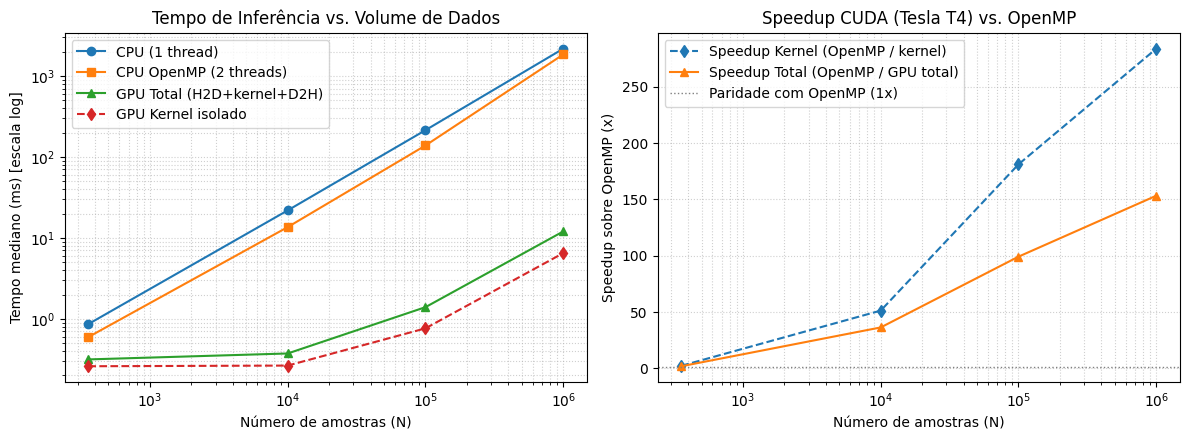

In [9]:
REPETICOES = 5
TAMANHOS = sorted({len(base), 10_000, 100_000, 1_000_000})

def medir(n):
    x = np.ascontiguousarray(base[np.arange(n) % len(base)])
    ref, paralelo, gpu = [np.empty(n, np.float32) for _ in range(3)]
    dx = cp.empty(x.shape, cp.float32)
    df = cp.empty(model.shape, cp.uint8)
    dy = cp.empty(n, cp.float32)
    ini, fim = cp.cuda.Event(), cp.cuda.Event()

    # 1. CPU sequencial (1 thread configurada fora da janela medida)
    cpu.configurar_omp(1)
    tempos_c1 = []
    for r in range(REPETICOES + 1):
        t0 = time.perf_counter()
        cpu_predict(x, model, ref)
        t1 = time.perf_counter()
        if r:
            tempos_c1.append((t1 - t0) * 1000.0)

    # 2. CPU paralela OpenMP (`threads` configuradas fora da janela medida)
    cpu.configurar_omp(threads)
    tempos_omp = []
    for r in range(REPETICOES + 1):
        t0 = time.perf_counter()
        cpu_predict(x, model, paralelo)
        t1 = time.perf_counter()
        if r:
            tempos_omp.append((t1 - t0) * 1000.0)

    # 3. GPU CUDA (kernel isolado e tempo total H2D + kernel + D2H)
    tempos_k, tempos_tot = [], []
    for r in range(REPETICOES + 1):
        cp.cuda.Stream.null.synchronize()
        t0 = time.perf_counter()
        dx.set(x)
        df.set(model)
        ini.record()
        launch(dx, df, dy, n)
        fim.record()
        dy.get(out=gpu)  # cópia bloqueante: aguarda conclusão do kernel
        t1 = time.perf_counter()
        km = cp.cuda.get_elapsed_time(ini, fim)
        if r:
            tempos_k.append(km)
            tempos_tot.append((t1 - t0) * 1000.0)

    erro = max(check(ref, paralelo), check(ref, gpu))
    c1 = float(np.median(tempos_c1))
    omp = float(np.median(tempos_omp))
    k = float(np.median(tempos_k))
    total = float(np.median(tempos_tot))
    return dict(
        N=n,
        CPU1_ms=c1,
        OpenMP_ms=omp,
        kernel_ms=k,
        GPU_total_ms=total,
        speedup_OMP=c1 / omp,
        speedup_kernel=omp / k,
        speedup_total=omp / total,
        GPU_amostras_s=n * 1000.0 / total,
        erro_max=erro,
    )

resultado = pd.DataFrame([medir(n) for n in TAMANHOS])
resultado.to_csv("resultados_inferencia.csv", index=False)
print(resultado.to_string(index=False, float_format=lambda v: f"{v:.6g}"))
print("\nLotes validados. Medianas gravadas em 'resultados_inferencia.csv'.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(resultado["N"], resultado["CPU1_ms"], "o-", label="CPU (1 thread)")
axes[0].plot(resultado["N"], resultado["OpenMP_ms"], "s-", label=f"CPU OpenMP ({threads} threads)")
axes[0].plot(resultado["N"], resultado["GPU_total_ms"], "^-", label="GPU Total (H2D+kernel+D2H)")
axes[0].plot(resultado["N"], resultado["kernel_ms"], "d--", label="GPU Kernel isolado")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Número de amostras (N)")
axes[0].set_ylabel("Tempo mediano (ms) [escala log]")
axes[0].set_title("Tempo de Inferência vs. Volume de Dados")
axes[0].grid(True, which="both", linestyle=":", alpha=0.6)
axes[0].legend()

axes[1].plot(resultado["N"], resultado["speedup_kernel"], "d--", label="Speedup Kernel (OpenMP / kernel)")
axes[1].plot(resultado["N"], resultado["speedup_total"], "^-", label="Speedup Total (OpenMP / GPU total)")
axes[1].axhline(1.0, color="gray", linestyle=":", linewidth=1, label="Paridade com OpenMP (1x)")
axes[1].set_xscale("log")
axes[1].set_xlabel("Número de amostras (N)")
axes[1].set_ylabel("Speedup sobre OpenMP (x)")
axes[1].set_title(f"Speedup CUDA ({gpu_name}) vs. OpenMP")
axes[1].grid(True, which="both", linestyle=":", alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.savefig("desempenho_cuda_vs_openmp.png", dpi=150)
plt.show()
